# R0 · Prise en main — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r0_prise_en_main/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R0.1 | vérifier ton exercice papier ✏️ | ✏️ | ★ | |
| A | R0.3 | Taper une fraction exacte, une expression et un intervalle | 📦 | ★ | 10 |
|  | R0.4 | Prédire : 0,1 + 0,2 vaut-il 0,3 pour Python ? | 🔮 | ★ | 10 |
|  | R0.5 | Vérifier un développement avec SymPy (expand, simplify) | 📦 | ★ | 15 |
|  | R0.6 | Chasse à l'erreur : `x^2` et `2x` en Python | 🐛 | ★ | 10 |
| B | R0.7 | Tracer une fonction avec matplotlib | 🎨 | ★ | 10 |
|  | R0.9 | Ta première fonction : la moyenne (`mean`) | 🔨 | ★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier ton calcul papier (partie 0), puis taper des réponses de toutes les sortes.
- Constater les arrondis des flottants et vérifier un calcul avec SymPy.
- Tracer une courbe propre et écrire ta première fonction de `mymath`.

**Rappel express.** La puissance s'écrit `**` ; la multiplication s'écrit toujours (`2*x`) ; `//` et `%` donnent le quotient et le reste ; une fraction, une expression et un intervalle se tapent entre guillemets (`"7/12"`, `"(x + 1)**2"`, `"]2 ; 5]"`) ; on compare des flottants avec `math.isclose`.

## Partie 0 · Vérifier ton exercice papier (✏️ R0.1)

Fais d'abord l'exercice R0.1 de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée (par exemple `23`), pas l'expression Python, sinon tu ne vérifies rien. Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0 needs no data: the answers are the values Python prints for each expression.

**Ex R0.1 — Calculer avec Python : priorités, division entière et reste**

In [3]:
wbm.record("R0.1a", 5 + 2 * 3 ** 2, mistakes={"** passe avant *, et * avant + : 3 ** 2 d'abord": 441, "** passe avant * : 2 * 3 ** 2 = 2 × 9": 41})
wbm.record("R0.1b", (5 + 2) * 3 ** 2, mistakes={"les parenthèses d'abord, puis ** avant * : 7 × 9": 441})
wbm.record("R0.1c", -4 ** 2, mistakes={"** passe avant le signe moins : -4 ** 2 se lit -(4 ** 2)": 16})
wbm.record("R0.1d", (-4) ** 2, mistakes={"avec les parenthèses, c'est (-4) qui est élevé au carré : moins par moins donne plus": -16})
wbm.record("R0.1e", 29 // 6, mistakes={"// donne le quotient entier, pas le reste": 5})
wbm.record("R0.1f", 29 % 6, mistakes={"% donne le reste, pas le quotient : 29 = 6 × 4 + 5": 4})
wbm.record("R0.1g", -29 // 6, mistakes={"// arrondit vers le bas (vers moins l'infini), pas vers zéro : -4,83… devient -5": -4})
wbm.record("R0.1h", -29 % 6, mistakes={"le reste est toujours entre 0 et 5 : écris -29 = 6 × (-5) + r": -5})
wbm.record("R0.1i", 4 ** 3 ** 0, mistakes={"les puissances se calculent de droite à gauche : 3 ** 0 d'abord": 1})
wbm.record("R0.1j", 10 / 4 * 2, decimals=1, mistakes={"/ et * se calculent de gauche à droite : (10 / 4) × 2": 1.25})

WBM_ANSWER {"hash": "1d6fba18a248bafcd90038e436d884294e2123779a417082de8d3ee7379464b6", "id": "R0.1a", "kind": "int", "magnitude": 1, "mistakes": {"924b76a43f0e76bf30658539cec86579912ca7c1aee738825dfb847678c1ca32": "** passe avant * : 2 * 3 ** 2 = 2 × 9", "c7dfbc0a35d60d9860ca1f72bdadaec634d8f0d94450412a5f7704d3176a3ccb": "** passe avant *, et * avant + : 3 ** 2 d'abord"}, "sign": 1}
📝 Ex R0.1a : réponse enregistrée (int).
WBM_ANSWER {"hash": "9d3cce9df9148c2797aac1d082dab6bbd3d40cac8a6fea3847a7f4a40bf15106", "id": "R0.1b", "kind": "int", "magnitude": 1, "mistakes": {"da7e5c7e0db9c17ef8525df262014667821b018389f22979ab2589ba07a8461c": "les parenthèses d'abord, puis ** avant * : 7 × 9"}, "sign": 1}
📝 Ex R0.1b : réponse enregistrée (int).
WBM_ANSWER {"hash": "1208049267f968f21e2f6e6ee879f4603baef551a68f8e5ec1f64a79fe704c5f", "id": "R0.1c", "kind": "int", "magnitude": 1, "mistakes": {"b6c18cb91b03937eaf92d32b9a892136ace7ba30c8f73450bd6d98b6bd980b68": "** passe avant le signe moins : -4 ** 

## Partie A · Taper, vérifier, calculer

Fiche §2 à §4. Tu tapes des réponses de toutes les sortes, tu constates les arrondis des flottants, et tu vérifies des calculs avec SymPy.

In [4]:
# Tools of the notebook (parts A and B)
import math
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

x = sp.Symbol("x")

### Ex R0.3 — Taper une fraction exacte, une expression et un intervalle 📦 ★ ⏱️ 10 min
**Objectif :** taper chaque sorte de réponse comme `wbm.check` l'attend.  
**Prérequis :** fiche §3 · **Parcours :** C, E

Calcule ou traduis chaque réponse **sur papier**, puis tape-la sous la bonne forme (fiche §3, tableau « Comment taper chaque sorte de réponse »).

| | Réponse demandée | Forme |
|---|---|---|
| a | $\dfrac{3}{4} - \dfrac{1}{6}$ | une fraction **irréductible**, entre guillemets |
| b | le carré de la somme de $x$ et de 3, moins 1 | une expression en $x$, entre guillemets |
| c | les réels strictement supérieurs à $-2$ et inférieurs ou égaux à 5 | un intervalle |
| d | les réels négatifs ou nuls | un intervalle |
| e | le nombre $\pi$ arrondi à 3 décimales | un nombre (tape le nombre, pas `math.pi`) |

In [5]:
wbm.record("R0.3a", Fraction(3, 4) - Fraction(1, 6), kind="fraction", simplified=True,
           mistakes={"1/6 = 2/12 : le numérateur aussi est multiplié par 2": "2/3",
                     "on ne soustrait pas les numérateurs et les dénominateurs entre eux": "-1"})
wbm.record("R0.3b", "(x + 3)**2 - 1", kind="expr", variables=("x",),
           mistakes={"le carré porte sur toute la somme x + 3 : des parenthèses autour de x + 3": "x + 3**2 - 1",
                     "le « moins 1 » vient après le carré, hors des parenthèses": "(x + 3 - 1)**2"})
wbm.record("R0.3c", "]-2 ; 5]", kind="interval",
           mistakes={"« strictement supérieurs » : -2 est exclu, et « inférieurs ou égaux » : 5 est inclus": "[-2 ; 5[",
                     "-2 est exclu (« strictement »), crochet ouvert de ce côté-là": "[-2 ; 5]"})
wbm.record("R0.3d", "]-oo ; 0]", kind="interval",
           mistakes={"« ou nuls » : 0 est inclus, donc crochet fermé en 0": "]-oo ; 0[",
                     "« négatifs » : ce sont les nombres inférieurs à 0, pas supérieurs": "[0 ; +oo["})
wbm.record("R0.3e", math.pi, decimals=3,
           mistakes={"arrondir n'est pas tronquer : π = 3,14159…, la 4e décimale (5) fait monter la 3e": 3.141})

WBM_ANSWER {"hash": "27c3520b27eccd4a09f9602025c4133a4946e426c40455c66fd445211c7c7909", "id": "R0.3a", "kind": "fraction", "mistakes": {"d55634d49b2777b7e9e1dbed520286e32c0d7b725542b8324a1a915ca4a3e076": "1/6 = 2/12 : le numérateur aussi est multiplié par 2", "f38683f982659e35f30fa7e85853fec1fd65b0a64a3502c70f98d05ea6e1732a": "on ne soustrait pas les numérateurs et les dénominateurs entre eux"}, "sign": 1, "simplified": true}
📝 Ex R0.3a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "fe39f106e2cf61d3bd904955aef522cce4b34a3bf7b90c7a813de6f5ccfb698f", "id": "R0.3b", "kind": "expr", "mistakes": {"3ea4ee679e35fe42c2dad316da7e770725633119355cceff0793dd3e7db42bcd": "le carré porte sur toute la somme x + 3 : des parenthèses autour de x + 3", "888d48efe3bff0be1856f848a1d11fdafd5a0517d4d606833ceb8d9c5f0feef9": "le « moins 1 » vient après le carré, hors des parenthèses"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R0.3b : réponse enregistrée (expr).

### Ex R0.4 — Prédire : 0,1 + 0,2 vaut-il 0,3 pour Python ? 🔮 ★ ⏱️ 10 min
**Objectif :** constater qu'un calcul en flottants est arrondi, et savoir comparer deux flottants.  
**Prérequis :** fiche §2 (lis « Les flottants » **après** l'exercice si tu ne l'as pas encore lue) · **Parcours :** C, E

**Avant d'exécuter quoi que ce soit**, prédis : pour Python, l'expression `0.1 + 0.2 == 0.3` vaut-elle `True` ou `False` ? Écris ta prédiction dans la cellule (un booléen, `True` ou `False`), vérifie-la, puis lance l'expérience.

In [6]:
wbm.record("R0.4a", 0.1 + 0.2 == 0.3, prediction=True)

WBM_ANSWER {"hash": "b60541503043778848caf01177c76583ead5a932616a3cb311351be76a5fec8e", "id": "R0.4a", "kind": "bool", "prediction": true}
📝 Ex R0.4a : réponse enregistrée (bool).


**L'expérience.** Elle ne s'exécute qu'une fois ta prédiction écrite.

In [7]:
print("0.1 + 0.2         =", 0.1 + 0.2)
print("0.1 + 0.2 == 0.3  :", 0.1 + 0.2 == 0.3)
print("écart             =", 0.1 + 0.2 - 0.3)
print("math.isclose      :", math.isclose(0.1 + 0.2, 0.3))
print("avec des Fraction :", Fraction(1, 10) + Fraction(2, 10))

0.1 + 0.2         = 0.30000000000000004
0.1 + 0.2 == 0.3  : False
écart             = 5.551115123125783e-17
math.isclose      : True
avec des Fraction : 3/10


**Après l'expérience**, lis les lignes affichées et réponds :
- b) l'écart s'affiche en notation scientifique, sous la forme `m e k`. Quel est l'entier $k$, c'est-à-dire la puissance de 10 de l'écart ?
- c) quelle est la valeur **exacte** de $\frac{1}{10} + \frac{2}{10}$ calculée avec `Fraction` ? Tape-la comme une fraction entre guillemets.

In [8]:
wbm.record("R0.4b", math.floor(math.log10(0.1 + 0.2 - 0.3)),
           mistakes={"e-17 veut dire « fois 10 puissance -17 » : l'exposant est négatif": 17})
wbm.record("R0.4c", Fraction(1, 10) + Fraction(2, 10), kind="fraction",
           mistakes={"avec Fraction, le calcul est exact : 1/10 + 2/10 n'a pas d'erreur d'arrondi": "3/11"})

WBM_ANSWER {"hash": "7949bee8d4cc629195dbdab401bea91be22bd416fc1188cc10d461317eed4002", "id": "R0.4b", "kind": "int", "magnitude": 1, "mistakes": {"85dc153b646e186357f8a4e6d68bb22c02557123665ad814a1abce1c57a67b9f": "e-17 veut dire « fois 10 puissance -17 » : l'exposant est négatif"}, "sign": -1}
📝 Ex R0.4b : réponse enregistrée (int).
WBM_ANSWER {"hash": "60491107cf140b5d9bc86fce046e2f9c3d5baafb44b005ec311beb9703bad1df", "id": "R0.4c", "kind": "fraction", "mistakes": {"86fb7d81b1093cf3b4da0647fd7d0a078a30f00769a08a0dd2569d3b1042e14a": "avec Fraction, le calcul est exact : 1/10 + 2/10 n'a pas d'erreur d'arrondi"}, "sign": 1}
📝 Ex R0.4c : réponse enregistrée (fraction).


💡 Retiens les deux remèdes : comparer avec une tolérance (`math.isclose`), ou calculer exactement avec `Fraction` quand les nombres sont des fractions.

### Ex R0.5 — Vérifier un développement avec SymPy (expand, simplify) 📦 ★ ⏱️ 15 min
**Objectif :** utiliser SymPy pour vérifier un calcul fait à la main, sans le faire à sa place.  
**Prérequis :** fiche §4 · **Parcours :** C, E

Un camarade a développé quatre expressions à la main :

| | Départ | Son résultat |
|---|---|---|
| a | $(x + 3)(x - 7)$ | $x^2 - 4x - 21$ |
| b | $(3x - 2)^2$ | $9x^2 - 4$ |
| c | $(x - 1)^3$ | $x^3 - 3x^2 + 3x - 1$ |
| d | $(x + 2)(x^2 - 2x + 4)$ | $x^3 - 8$ |

1. Avec `sp.expand`, trouve **lesquels sont justes** (la méthode de la fiche : la différence se développe-t-elle en 0 ?). Réponds par les lettres des résultats justes, dans l'ordre alphabétique, par exemple `"ab"`.
2. Donne le bon développement de b), sous forme d'expression.
3. Avec `sp.simplify`, simplifie $\dfrac{x^2 - 4}{x + 2}$ et tape la forme simplifiée.

`x` est déjà une lettre SymPy (cellule des outils, partie A).

In [9]:
claims = {"a": ((x + 3)*(x - 7), x**2 - 4*x - 21),
          "b": ((3*x - 2)**2, 9*x**2 - 4),
          "c": ((x - 1)**3, x**3 - 3*x**2 + 3*x - 1),
          "d": ((x + 2)*(x**2 - 2*x + 4), x**3 - 8)}
for letter, (start, result) in claims.items():
    difference = sp.expand(start - result)
    print(letter, "juste" if difference == 0 else f"faux (il reste {difference})")
print("b) bon développement :", sp.expand((3*x - 2)**2))
print("simplification       :", sp.simplify((x**2 - 4) / (x + 2)))

a juste
b faux (il reste 8 - 12*x)
c juste
d faux (il reste 16)
b) bon développement : 9*x**2 - 12*x + 4
simplification       : x - 2


In [10]:
wbm.record("R0.5a", "ac",
           mistakes={"b) est faux : le carré d'une différence a un « double produit », -12x": "abc",
                     "d) est faux : développe-le, le dernier terme vaut 2 × 4 = +8": "acd",
                     "c) est juste : sp.expand((x - 1)**3) redonne exactement son résultat": "a",
                     "a) est juste : la différence se développe en 0": "c"})
wbm.record("R0.5b", sp.expand((3*x - 2)**2), kind="expr", variables=("x",),
           mistakes={"le double produit vaut 2 × 3x × 2 = 12x": "9*x**2 - 6*x + 4",
                     "le dernier terme est (-2)² = +4": "9*x**2 - 12*x - 4"})
wbm.record("R0.5c", sp.simplify((x**2 - 4) / (x + 2)), kind="expr", variables=("x",),
           mistakes={"x² - 4 = (x - 2)(x + 2) : quand on simplifie par x + 2, il reste x - 2": "x + 2"})

WBM_ANSWER {"hash": "54c02fc4b883a1eb3efc552f7f809331880c1d9799310fc8213a33696e90c70d", "id": "R0.5a", "kind": "str", "mistakes": {"12977e8783b49146d784f71b8d20e194abfd98c04af91d23f91043cf3fa048dd": "d) est faux : développe-le, le dernier terme vaut 2 × 4 = +8", "7210673650c28e33e2d14e5599b1dc0bd8a41a751e8243d53c2eb95b3c868afb": "c) est juste : sp.expand((x - 1)**3) redonne exactement son résultat", "8d51fcf97957fbd750277c3e620bab257b43da5e26590b78f6ad59eb5e35ea21": "b) est faux : le carré d'une différence a un « double produit », -12x", "9a96789068c6173433c10e35b7fac8a5ef97ebaef6702c34f5ef2ed19eb1ee49": "a) est juste : la différence se développe en 0"}}
📝 Ex R0.5a : réponse enregistrée (str).
WBM_ANSWER {"hash": "fef22b0c52ca4d628cef41d196ebdb1b98161b2ed42f23703233c8b6f1829516", "id": "R0.5b", "kind": "expr", "mistakes": {"96b032c34b898988c112376f7df17de28094e01fa6630b213b2b89cb24e319cb": "le double produit vaut 2 × 3x × 2 = 12x", "b44bf3aa2ba1e9bdd3efb7d65016f70e5fc06853c04717940e6f8

💡 `sp.expand(depart - resultat) == 0` prouve l'égalité ; remplacer x par un nombre ne fait que la tester.

### Ex R0.6 — Chasse à l'erreur : `x^2` et `2x` en Python 🐛 ★ ⏱️ 10 min
**Objectif :** repérer les écritures de formules que Python lit autrement que les maths.  
**Prérequis :** fiche §2 et §4 · **Parcours :** C, E

Chaque ligne veut calculer la formule écrite en commentaire, pour un nombre `x` déjà défini. **Sans rien exécuter**, trouve les lignes fausses : soit elles provoquent une erreur, soit elles calculent autre chose que la formule.

```python
y1 = 3*x**2 - 5*x      # (a)  3x² − 5x
y2 = x^3               # (b)  x³
y3 = 1/4*x             # (c)  1/(4x)
y4 = (x - 1)**2        # (d)  (x − 1)²
y5 = -x**2             # (e)  −x²
y6 = 5x + 1            # (f)  5x + 1
y7 = x**(1/2)          # (g)  √x
```

1. Donne les lettres des lignes fausses, dans l'ordre alphabétique (par exemple `"ab"`).
2. Écris la fonction `y3` corrigée, qui calcule vraiment $\dfrac{1}{4x}$ ; la vérification calcule `y3(2)`.

In [11]:
def y3(x):
    """Line (c), corrected: return 1/(4x)."""
    return 1 / (4 * x)


print("y3(2) =", y3(2))
print("ce que calculait la ligne (c) pour x = 2 :", 1/4*2)

y3(2) = 0.125
ce que calculait la ligne (c) pour x = 2 : 0.5


In [12]:
wbm.record("R0.6a", "bcf",
           mistakes={"il manque une ligne fautive : en Python, ^ n'est pas la puissance": "cf",
                     "il manque une ligne fautive : 1/4*x se calcule (1/4) × x, pas 1/(4x)": "bf",
                     "il manque une ligne fautive : la multiplication ne se sous-entend pas en Python": "bc",
                     "une ligne de trop : la ligne (a) est correcte ; relis ce qu'elle fait": "abcf",
                     "une ligne de trop : la ligne (d) est correcte ; relis ce qu'elle fait": "bcdf",
                     "une ligne de trop : la ligne (e) est correcte ; relis ce qu'elle fait": "bcef",
                     "une ligne de trop : la ligne (g) est correcte ; relis ce qu'elle fait": "bcfg",
                     "la ligne (a) est correcte, et il manque une ligne fautive : en Python, ^ n'est pas la puissance": "acf",
                     "la ligne (d) est correcte, et il manque une ligne fautive : en Python, ^ n'est pas la puissance": "cdf",
                     "la ligne (e) est correcte, et il manque une ligne fautive : en Python, ^ n'est pas la puissance": "cef",
                     "la ligne (g) est correcte, et il manque une ligne fautive : en Python, ^ n'est pas la puissance": "cfg",
                     "la ligne (a) est correcte, et il manque une ligne fautive : 1/4*x se calcule (1/4) × x, pas 1/(4x)": "abf",
                     "la ligne (d) est correcte, et il manque une ligne fautive : 1/4*x se calcule (1/4) × x, pas 1/(4x)": "bdf",
                     "la ligne (e) est correcte, et il manque une ligne fautive : 1/4*x se calcule (1/4) × x, pas 1/(4x)": "bef",
                     "la ligne (g) est correcte, et il manque une ligne fautive : 1/4*x se calcule (1/4) × x, pas 1/(4x)": "bfg",
                     "la ligne (a) est correcte, et il manque une ligne fautive : la multiplication ne se sous-entend pas en Python": "abc",
                     "la ligne (d) est correcte, et il manque une ligne fautive : la multiplication ne se sous-entend pas en Python": "bcd",
                     "la ligne (e) est correcte, et il manque une ligne fautive : la multiplication ne se sous-entend pas en Python": "bce",
                     "la ligne (g) est correcte, et il manque une ligne fautive : la multiplication ne se sous-entend pas en Python": "bcg"})
wbm.record("R0.6b", 1 / (4 * 2), decimals=4,
           mistakes={"1/4*x se lit (1/4) × x : il faut des parenthèses, 1/(4*x)": 0.5})

WBM_ANSWER {"hash": "b07fb2f2c2d8e49900017a0e57040c00b3f06f1e0030c55635fb239ae42a5f66", "id": "R0.6a", "kind": "str", "mistakes": {"18da5c0a3c69cd106fb5e42f446e40e6e42323ea3b0ff7b52ae3095493206591": "il manque une ligne fautive : la multiplication ne se sous-entend pas en Python", "31e59c1a9dff5464eb039de7b86b6a5f83f691a15316747a411c81dfd144bfb5": "il manque une ligne fautive : 1/4*x se calcule (1/4) × x, pas 1/(4x)", "380162548018d0e9e2efe34a5c441a7fcc823a45635fd96890cf008c67e39e92": "la ligne (a) est correcte, et il manque une ligne fautive : la multiplication ne se sous-entend pas en Python", "41b5d387c14252d01188a4f2bde9e58ac6e8aa955e4c7ecfbfc42c9e04e5c29c": "une ligne de trop : la ligne (g) est correcte ; relis ce qu'elle fait", "45ee2f19a46de3e13a36acd0963f00acbd27cacf7a98a17db548dfff4c5dc348": "la ligne (g) est correcte, et il manque une ligne fautive : la multiplication ne se sous-entend pas en Python", "46e05752110f2814c22327920f6ea7876575761020fa5052490b154c51acf51b": "une li

💡 (e) est juste : `-x**2` vaut $-(x^2)$, exactement comme la formule $-x^2$. Et (g) est juste : `x**(1/2)` est la racine carrée (pour x ≥ 0).

## Partie B · Tracer et programmer

Fiche §6 et §7. Une courbe propre, puis ta première fonction de `mymath` et ses tests.

### Ex R0.7 — Tracer une fonction avec matplotlib 🎨 ★ ⏱️ 10 min
**Objectif :** tracer proprement la courbe d'une fonction et y lire des valeurs.  
**Prérequis :** fiche §6 · **Parcours :** C

Complète la fonction `plot_f` pour qu'elle trace la courbe de $f(x) = x^2 - 2x - 3$ sur l'intervalle $[-2 ; 4]$, en suivant la recette de la fiche (§6) : 200 points, un titre, le nom des deux axes, un quadrillage, une légende, et l'axe horizontal $y = 0$ en trait fin (`ax.axhline(0, linewidth=0.8)`).

Puis **lis sur ta courbe**, et écris dans ta copie de `06_mes_reponses.md` : les abscisses des points où la courbe coupe l'axe horizontal, et les coordonnées de son point le plus bas. Compare ensuite ta figure et tes lectures à celles de `05_solutions.md`.

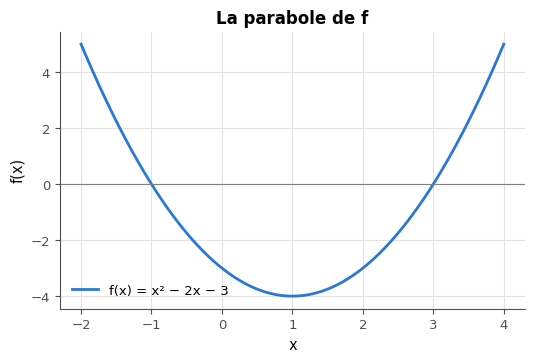

In [13]:
def plot_f():
    """Draw f(x) = x**2 - 2*x - 3 on [-2, 4]: title, axis labels, grid, legend and the line y = 0."""
    xs = np.linspace(-2, 4, 200)
    ys = xs**2 - 2*xs - 3
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.plot(xs, ys, label="f(x) = x² − 2x − 3")
    ax.axhline(0, linewidth=0.8, color="gray")
    ax.set_title("La parabole de f")
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.grid(True)
    ax.legend()
    plt.show()


plot_f()

### Ex R0.9 — Ta première fonction : la moyenne (`mean`) 🔨 ★ ⏱️ 25 min
**Objectif :** écrire une fonction de `mymath` d'après son contrat, la tester et écrire ses propres tests.  
**Prérequis :** fiche §7 ; workbookIA 0A §100.5.1 (définir une fonction) · **mymath :** `_example.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`.** Ouvre ta copie `mon_travail/mymath/_example.py` (créée par `python tools/start_chapter.py R0` ; sur Colab, `00_setup/COLAB.md`, « Modifier tes fichiers `.py` »). Lis la docstring de `mean` en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie.

1. Écris `mean(values)` dans `mon_travail/mymath/_example.py` : la somme des valeurs divisée par leur nombre, sous forme de flottant ; une `ValueError` si la suite est vide. Fiche §7, et son piège : teste le vide avec `len(values) == 0`.
2. Lance les tests de `mean` (cellule « tests ») : ils comparent ta fonction à `np.mean`.
3. Écris **tes propres tests** dans `my_tests` : deux lignes `assert`, l'une sur une liste de deux nombres dont tu connais la moyenne de tête, l'autre sur une liste d'un seul nombre.

Si tu as déjà fait l'exercice 0A.26 de workbookIA, tu reconnais le mécanisme : ici, c'est ta librairie de maths.

In [14]:
mymath = wbm.load_mymath("ref")
print("mean([2, 4, 9]) =", mymath._example.mean([2, 4, 9]))

mean([2, 4, 9]) = 5.0


In [15]:
wbm.record("R0.9", 5.0, decimals=4,
           mistakes={"divise par le nombre de valeurs (3), pas par 2": 7.5,
                     "on veut la moyenne, pas la somme : divise par le nombre de valeurs": 15})

WBM_ANSWER {"decimals": 4, "hash": "5f5967bc51b2fb9f139eed227daeb589862251df1f52d15586aca710a522a9b1", "hash_coarse": "31f1eabb53d85e7eb88dd718b43d635fc5545c96d4a02a7dac652cbb780b2a41", "id": "R0.9", "kind": "float", "magnitude": 0, "mistakes": {"8f05cd2a006c816a71c41fb254a8c5ed9b521cfe5c2058a65778880b6f7607f7": "on veut la moyenne, pas la somme : divise par le nombre de valeurs", "c53c2a8063c0037a9d2d7c2e8ef13050f8173a48e85ddc28ef3395b3fc7873a6": "divise par le nombre de valeurs (3), pas par 2"}, "sign": 1}
📝 Ex R0.9 : réponse enregistrée (float, 4 décimale(s)).


**Les tests de `mean`** (fiche §7 : lis d'abord la ligne qui suit chaque ❌, elle dit ce qui était attendu).

In [16]:
from wbm.nbtools import run_pytest_group

run_pytest_group("tests/test_example_mymath.py", "test_mean", impl="ref")

pytest: 5 passed in 0.01s


**Tes propres tests.** Deux lignes `assert` dans `my_tests` (question 3).

In [17]:
def my_tests():
    """Two asserts of your own on mymath._example.mean (question 3)."""
    assert mymath._example.mean([10, 20]) == 15.0
    assert mymath._example.mean([7]) == 7.0


my_tests()
print("✅ Ex R0.9 : les deux assert passent.")

✅ Ex R0.9 : les deux assert passent.


💡 Un `assert` qui passe n'affiche rien ; c'est quand il échoue qu'il parle (`AssertionError`).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu prévoir ce que Python calcule pour `-3 ** 2`, `17 // 5` ou `2 ** 3 ** 2`, et pourquoi `0.1 + 0.2 == 0.3` est faux ?
2. Sais-tu taper une fraction, une expression et un intervalle pour `wbm.check`, et vérifier un développement avec SymPy ?
3. Sais-tu écrire une fonction de `mymath` d'après sa docstring, lancer ses tests et lire un échec ?

**La suite** : le test de positionnement (`python tools/start_chapter.py POS`), puis R1. Dans workbookIA, continue le chapitre 0A (jusqu'à §100.6.2 avant R1).